In [102]:
import datetime as dt  
from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.featured_tracking.area_tracker import AreaTracker
from py_eddy_tracker.gui import GUI
from py_eddy_tracker.tracking import Correspondances
from py_eddy_tracker.observations.tracking import TrackEddiesObservations

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
import numpy as np
from numba import njit
import glob
import os
import sys
from netCDF4 import Dataset
from time import ctime

In [20]:
def isAC(st):
    if 'AC' in st.split('.'):
        return True
    else:
        return False
def isCC(st):
    if 'CC' in st.split('.'):
        return True
    else:
        return False
def isAll(st):
    if 'all' in st.split('.'):
        return True
    else:
        return False
Outdir=rf'.\Data\output'  #识别数据存放路径

files = [Outdir+'\\'+name for name in os.listdir(Outdir) if os.path.isdir(os.path.join(Outdir, name))]
ACs = list(filter(isAC, files))
CCs = list(filter(isCC, files))

In [110]:
for i in range(len(ACs)):
    file_list_AC = list(filter(isAll, glob.glob(ACs[0]+'\\*.nc')))
    file_list_CC = list(filter(isAll, glob.glob(CCs[0]+'\\*.nc')))
    
    a = Correspondances(datasets=file_list_AC, class_method=AreaTracker, virtual=3)
    a.track();a.prepare_merging()
    AC_eddies_area_tracker = a.merge(raw_data=False)
    AC_eddies_area_tracker.virtual[:] = AC_eddies_area_tracker.time == 0
    AC_eddies_area_tracker.filled_by_interpolation(AC_eddies_area_tracker.virtual == 1)
    
    c = Correspondances(datasets=file_list_CC, class_method=AreaTracker, virtual=3)
    c.track();c.prepare_merging()
    CC_eddies_area_tracker = c.merge(raw_data=False)
    CC_eddies_area_tracker.virtual[:] = CC_eddies_area_tracker.time == 0
    CC_eddies_area_tracker.filled_by_interpolation(CC_eddies_area_tracker.virtual == 1)
    with Dataset('tmp_AC.nc', 'w') as wnc:
        AC_eddies_area_tracker.to_netcdf(wnc)
    with Dataset('tmp_CC.nc', 'w') as wnc:
        CC_eddies_area_tracker.to_netcdf(wnc)

In [25]:
AC_eddies_area_tracker.nb_tracks

117

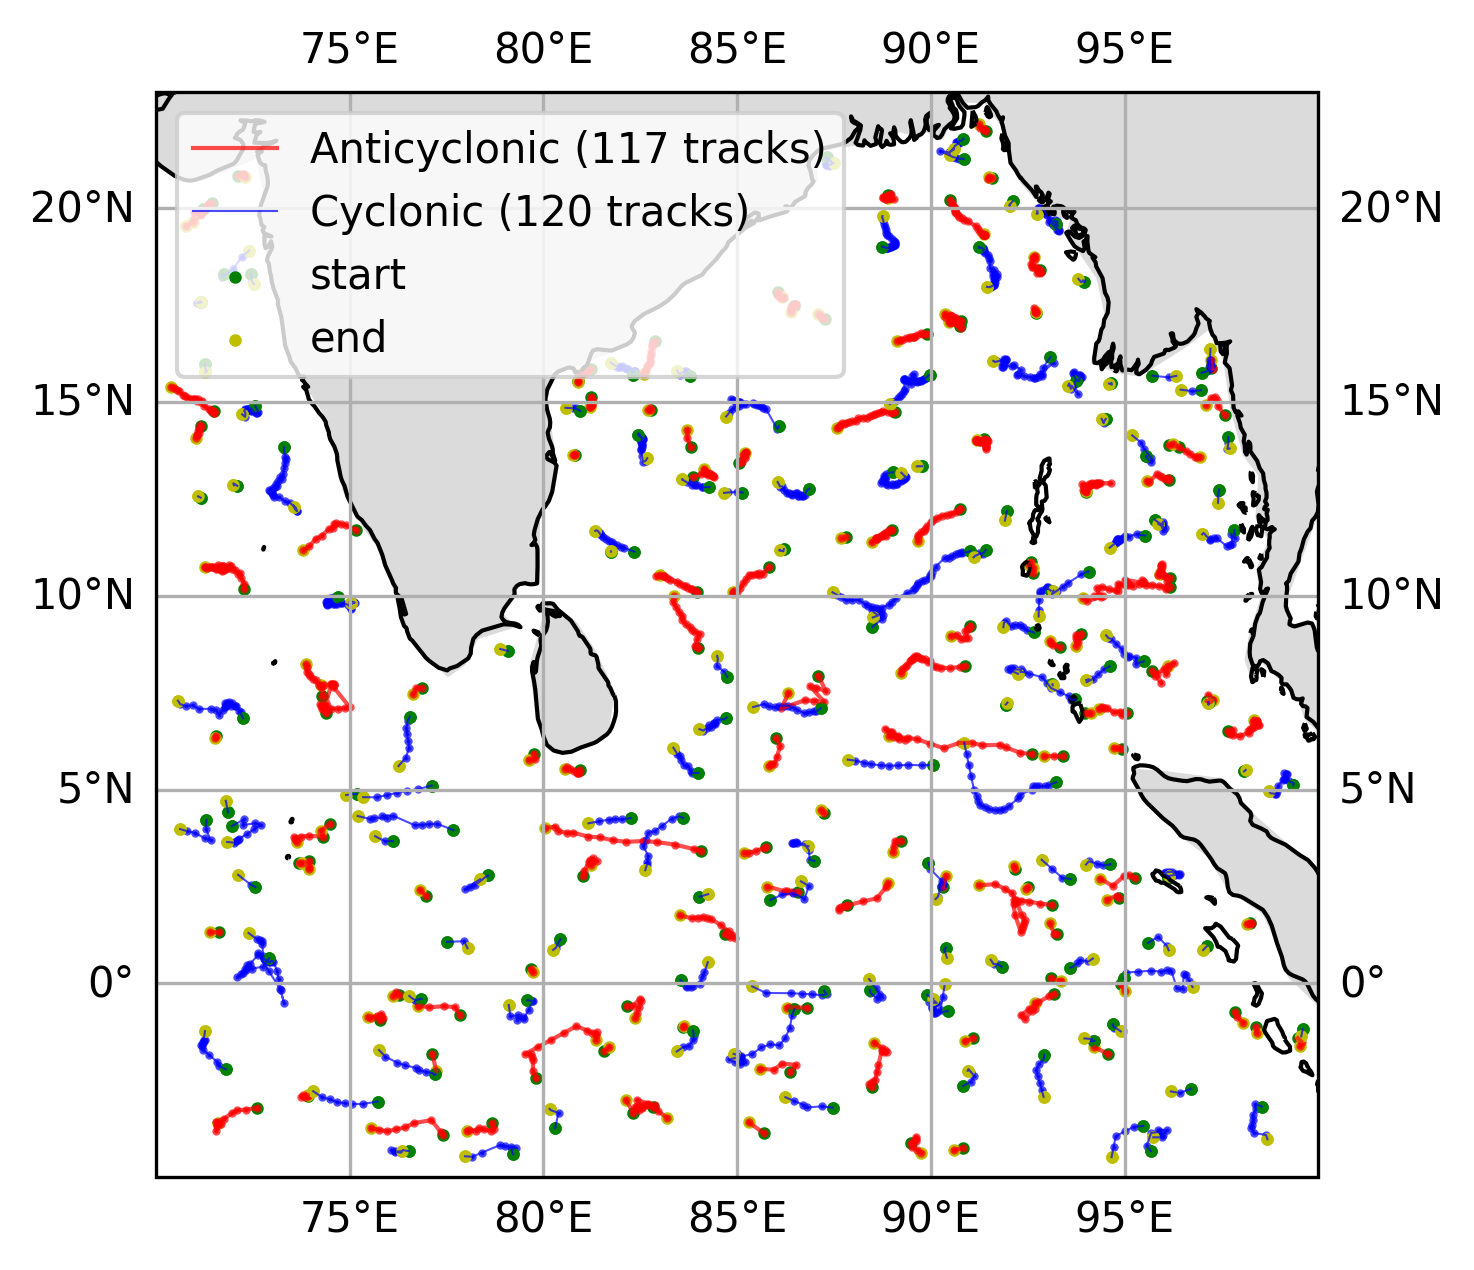

In [81]:
g, axs = plt.subplots(1,1,figsize=(5,5),dpi=300,subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)})
ax = axs
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(-5, 23)
AC_eddies_area_tracker.plot(ax, ref=-10, label="Anticyclonic ({nb_tracks} tracks)", color="r", lw=1,alpha=0.7)
CC_eddies_area_tracker.plot(ax, ref=-10, label="Cyclonic ({nb_tracks} tracks)", color="b", lw=0.5,alpha=0.7)
AC_eddies_area_tracker.first_obs().scatter(ax,color='g',s=4,label="start")
AC_eddies_area_tracker.last_obs().scatter(ax,color='y',s=4,label="end")
ax.legend()
AC_eddies_area_tracker.scatter(ax, color="r", s=1,alpha=0.7)
CC_eddies_area_tracker.scatter(ax, color="b", s=1,alpha=0.7)
CC_eddies_area_tracker.first_obs().scatter(ax,color='g',s=4)
CC_eddies_area_tracker.last_obs().scatter(ax,color='y',s=4)
CC_eddies_area_tracker.first_obs().scatter(ax,color='g',s=4)
CC_eddies_area_tracker.last_obs().scatter(ax,color='y',s=4)

ax.gridlines(draw_labels=True)

C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: divide by zero encountered in true_divide
  ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: invalid value encountered in true_divide
  ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: divide by zero encountered in true_divide
  ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: invalid value encountered in true_divide
  ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: divide by zero encountered in true_divide
  ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
C:\Users\53150\AppData\Local\Temp\ipykernel_1892\3798330920.py:32: RuntimeWarning: invalid v

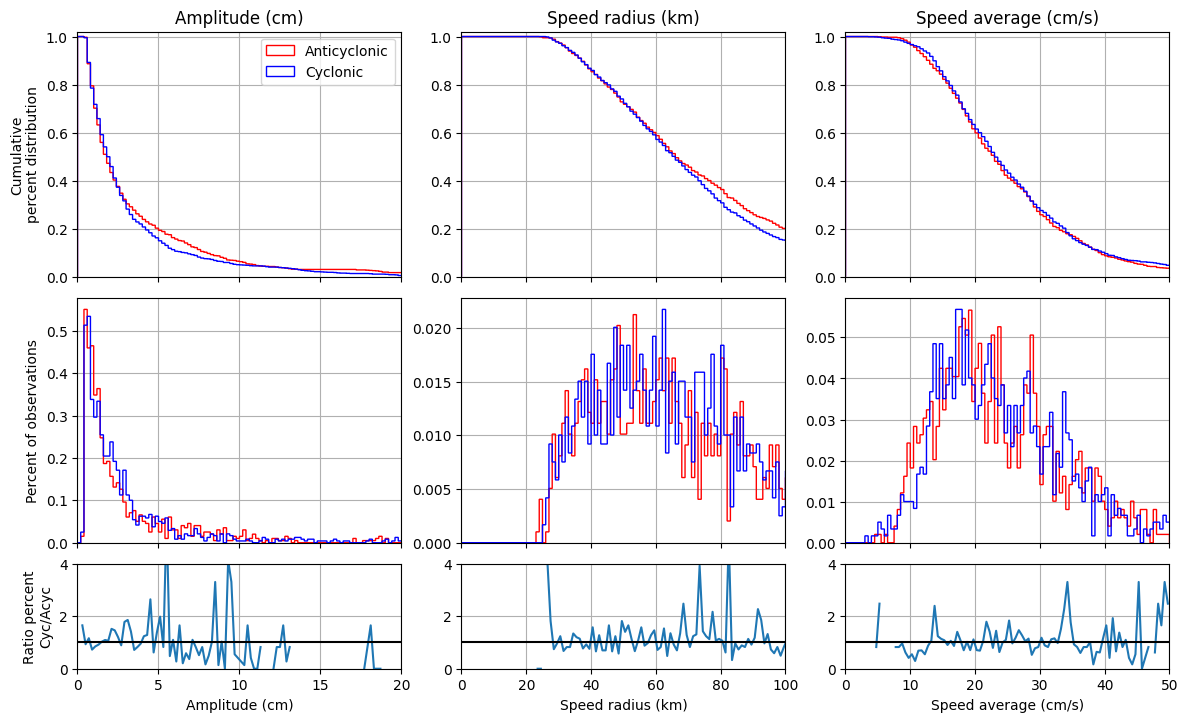

In [96]:
kwargs_a = dict(label="Anticyclonic", color="r", histtype="step", density=True)
kwargs_c = dict(label="Cyclonic", color="b", histtype="step", density=True)
fig = plt.figure(figsize=(12, 7))

for x0, name, title, xmax, factor, bins in zip(
    (0.4, 0.72, 0.08),
    ("speed_radius", "speed_average", "amplitude"),
    ("Speed radius (km)", "Speed average (cm/s)", "Amplitude (cm)"),
    (100, 50, 20),
    (0.001, 100, 100),
    (np.arange(0, 2000, 1), np.arange(0, 1000, 0.5), np.arange(0.0005, 1000, 0.2)),
):
    ax_hist = fig.add_axes((x0, 0.24, 0.27, 0.35))
    nb_a, _, _ = ax_hist.hist(AC_eddies_area_tracker[name] * factor, bins=bins, **kwargs_a)
    nb_c, _, _ = ax_hist.hist(CC_eddies_area_tracker[name] * factor, bins=bins, **kwargs_c)
    ax_hist.set_xticklabels([])
    ax_hist.set_xlim(0, xmax)
    ax_hist.grid()

    ax_cum = fig.add_axes((x0, 0.62, 0.27, 0.35))
    ax_cum.hist(AC_eddies_area_tracker[name] * factor, bins=bins, cumulative=-1, **kwargs_a)
    ax_cum.hist(CC_eddies_area_tracker[name] * factor, bins=bins, cumulative=-1, **kwargs_c)
    ax_cum.set_xticklabels([])
    ax_cum.set_title(title)
    ax_cum.set_xlim(0, xmax)
    ax_cum.set_ylim(0, 1.02)
    ax_cum.grid()

    ax_ratio = fig.add_axes((x0, 0.06, 0.27, 0.15))
    ax_ratio.set_xlim(0, xmax)
    ax_ratio.set_ylim(0, 4)
    ax_ratio.plot((bins[1:] + bins[:-1]) / 2, nb_c / nb_a)
    ax_ratio.axhline(1, color="k")
    ax_ratio.grid()
    ax_ratio.set_xlabel(title)

ax_cum.set_ylabel("Cumulative\npercent distribution")
ax_hist.set_ylabel("Percent of observations")
ax_ratio.set_ylabel("Ratio percent\nCyc/Acyc")
ax_cum.legend()

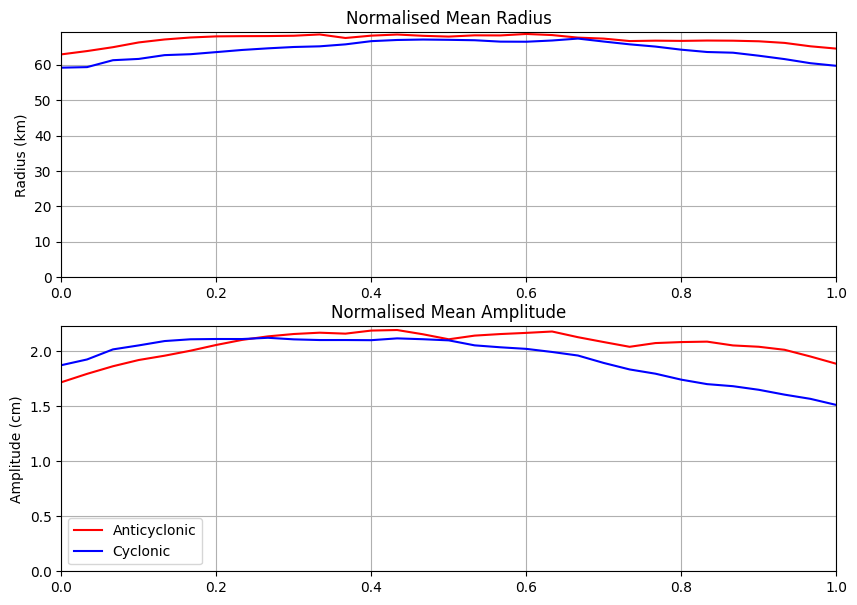

In [119]:
@njit(cache=True)
def sum_profile(x_new, y, out):
    """Will sum all interpolated given array"""
    out += np.interp(x_new, np.linspace(0, 1, y.size), y)
    
class MyObs(TrackEddiesObservations):
    def eddy_norm_lifetime(self, name, nb, factor=1):
        """
        :param str,array name: Array or field name
        :param int nb: size of output array
        """
        y = self.parse_varname(name)
        x = np.linspace(0, 1, nb)
        out = np.zeros(nb, dtype=y.dtype)
        nb_track = 0
        for i, b0, b1 in self.iter_on("track"):
            y_ = y[i]
            size_ = y_.size
            if size_ == 0:
                continue
            sum_profile(x, y_, out)
            nb_track += 1
        return x, out / nb_track * factor
kw = dict(include_vars=("speed_radius", "amplitude", "track"))
a = MyObs.load_file('tmp_AC.nc', **kw)
c = MyObs.load_file('tmp_CC.nc', **kw)

nb_max_a = a.nb_obs_by_track.max()
nb_max_c = c.nb_obs_by_track.max()

# Radius
AC_radius = a.eddy_norm_lifetime("speed_radius", nb=nb_max_a, factor=1e-3)
CC_radius = c.eddy_norm_lifetime("speed_radius", nb=nb_max_c, factor=1e-3)
# Amplitude
AC_amplitude = a.eddy_norm_lifetime("amplitude", nb=nb_max_a, factor=1e2)
CC_amplitude = c.eddy_norm_lifetime("amplitude", nb=nb_max_c, factor=1e2)

fig, (ax0, ax1) = plt.subplots(nrows=2, figsize=(10,7))

ax0.set_title("Normalised Mean Radius")
ax0.plot(*AC_radius,color='r'), ax0.plot(*CC_radius,color='b')
ax0.set_ylabel("Radius (km)"), ax0.grid()
ax0.set_xlim(0, 1), ax0.set_ylim(0, None)

ax1.set_title("Normalised Mean Amplitude")
ax1.plot(*AC_amplitude, label="Anticyclonic",color='r'), ax1.plot(*CC_amplitude, label="Cyclonic",color='b')
ax1.set_ylabel("Amplitude (cm)"), ax1.grid(), ax1.legend()
_ = ax1.set_xlim(0, 1), ax1.set_ylim(0, None)

(None, <matplotlib.legend.Legend at 0x1816a8b8fd0>)

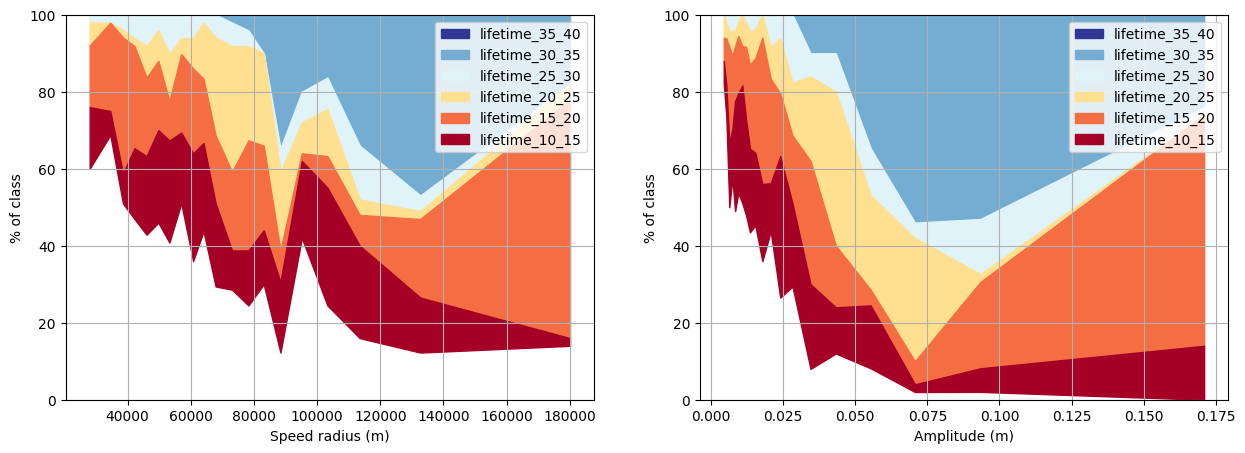

In [138]:
groups = dict()
bins_time = np.arange(10,45,5)
for t0, t1 in zip(bins_time[:-1], bins_time[1:]):
    groups[f"lifetime_{t0}_{t1}"] = lambda dataset, t0=t0, t1=t1: (
        dataset.lifetime >= t0
    ) * (dataset.lifetime < t1)
bins_percentile = np.arange(0, 100.0001, 5)
def stats_compilation(dataset, groups, field, bins, filter=None):
    datas = dict(ref=dataset.bins_stat(field, bins=bins, mask=filter)[1], y=dict())
    for k, index in groups.items():
        i = dataset.merge_filters(filter, index)
        x, datas["y"][k] = dataset.bins_stat(field, bins=bins, mask=i)
    datas["x"], datas["bins"] = x, bins
    return datas


def plot_stats(ax, bins, x, y, ref, box=False, cmap=None, percentiles=None, **kw):
    base, ref = np.ones(x.shape) * 100.0, ref / 100.0
    x = np.arange(bins.shape[0]).repeat(2)[1:-1] if box else x
    y0 = base
    if cmap is not None:
        cmap, nb_groups = plt.get_cmap(cmap), len(y)
    keys = tuple(y.keys())
    for i, k in enumerate(keys[::-1]):
        y1 = y0 - y[k] / ref
        args = (y0.repeat(2), y1.repeat(2)) if box else (y0, y1)
        if cmap is not None:
            kw["color"] = cmap(1 - i / (nb_groups - 1))
        ax.fill_between(x, *args, label=k, **kw)
        y0 = y1
    if percentiles:
        for b in bins:
            ax.axvline(b, **percentiles)
stats = stats_compilation(
    a, groups, "radius_s", np.percentile(a.radius_s, bins_percentile)
)
fig = plt.figure(figsize=[15,5])
ax = fig.add_subplot(121)
plot_stats(ax, **stats, cmap="RdYlBu")
ax.set_xlabel("Speed radius (m)"), ax.set_ylabel("% of class"), ax.set_ylim(0, 100)
ax.grid(), ax.legend()
ax = fig.add_subplot(122)
stats = stats_compilation(
    a, groups, "amplitude", np.percentile(a.amplitude, bins_percentile)
)
plot_stats(ax, **stats, cmap="RdYlBu")
ax.set_xlabel("Amplitude (m)"), ax.set_ylabel("% of class"), ax.set_ylim(0, 100)
ax.grid(), ax.legend()

(None, <matplotlib.legend.Legend at 0x1816a214850>)

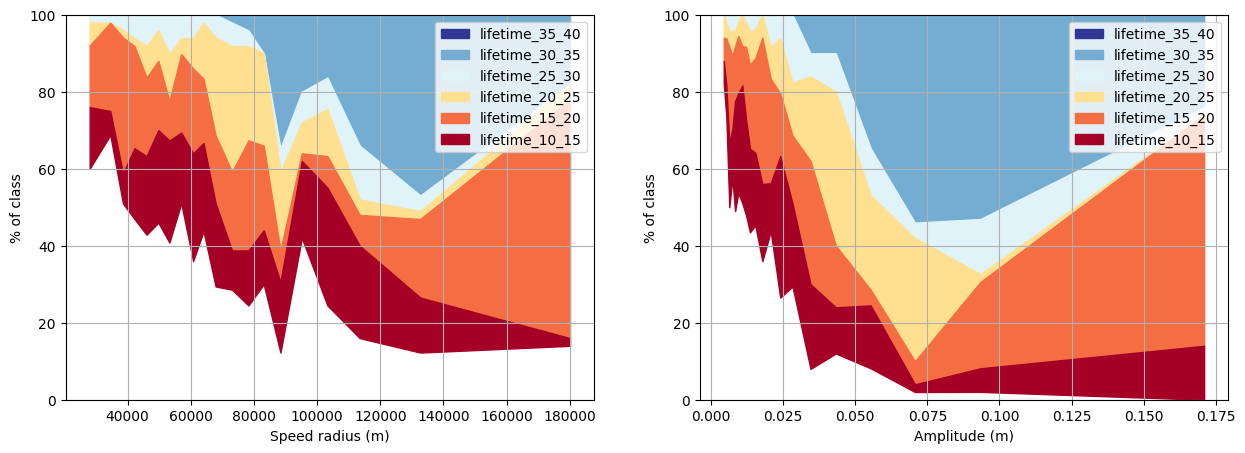